# `ppc_gwtc5_k5`

The weakly modelled population of `model.py`:

$$p(\ln m_1, q, \chi_\mathrm{eff}, \chi_p) = p_\mathrm{mass}(\ln m_1, q)\; p(\chi_\mathrm{eff}, \chi_p \mid \ln m_1, q)$$

- **Mass:** PixelPop's Matérn field on 100 × 100 bins in $(\ln m_1, q)$, $m_1 \in [3, 200]\,M_\odot$, times the
  $m_2 > 3\,M_\odot$ window.
- **Spins:** a Matérn log density on 100 × 100 bins in $(\chi_\mathrm{eff}, \chi_p)$, on the physical region
  $\chi_p < \chi_{p,\max}(\chi_\mathrm{eff}, q)$. Its shape changes with mass through the lowest $k \times k$ mass
  modes. There are no gates, no channels and no 2G template.

Catalog `gwtc5`. The cells below read the chain as it is on disk, so re-running the notebook picks up a chain that
has grown or finished. **Caveats** are printed with the chain summary: chain length, number of chains, and whether the
run finished.

In [1]:
import os
os.environ.setdefault('JAX_PLATFORMS', 'cpu')
os.environ.setdefault('XLA_FLAGS', '--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1')
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(v, '1')
import sys
REPO = '/mnt/home/jheinzel/bbh-pixelpop-constraints'
sys.path.insert(0, REPO)
import glob, pickle
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpyro.diagnostics import effective_sample_size, split_gelman_rubin
from pixelpop.models.gwpop_models import PlanckWindow_SecondaryMass
%matplotlib inline
import plot_style
plot_style.apply()
from model import SPIN_REF_MASSES

RUN = 'ppc_gwtc5_k5'
CATALOG = 'gwtc5'
RUN_DIR = os.path.join(REPO, 'results', RUN)
MIN_M, MAX_M = 3., 200.
lnm_edges = np.linspace(np.log(MIN_M), np.log(MAX_M), 101)
q_edges = np.linspace(0., 1., 101)
e_edges = np.linspace(-1., 1., 101)
p_edges = np.linspace(0., 1., 101)
centres = lambda e: 0.5 * (e[1:] + e[:-1])
lnm_c, q_c, e_c, p_c = map(centres, (lnm_edges, q_edges, e_edges, p_edges))
dlnm, dq, de, dp = (np.diff(e)[0] for e in (lnm_edges, q_edges, e_edges, p_edges))

/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/mnt/home/jheinzel/venvs/gwjax313/lib/python3.13/site-packages/htcondor/__init__.py:49: UserWarning: Neither the environment variable CONDOR_CONFIG, /etc/condor/, /usr/local/etc/, nor ~condor/ contain a condor_config source. Therefore, we are using a null condor_config.
  _warnings.warn(message)


## Chain summary and convergence

In [2]:
SKIP = ('_eigenbasis_sites', '_spin_sites', '_spin0_sites', '_spin1_sites', '_gauss_sites')   # white noise: not needed
files = sorted(glob.glob(os.path.join(RUN_DIR, 'chain_*_samples.h5')))
chains = []
for f in files:
    with h5py.File(f, 'r') as h:
        chains.append({k: h[k][()] for k in h if k not in SKIP})
n_draws = min(len(c['log_likelihood']) for c in chains)
S = {k: np.stack([c[k][:n_draws] for c in chains]) for k in chains[0]}     # (chains, draws, ...)
flat = {k: v.reshape(-1, *v.shape[2:]) for k, v in S.items()}
print(f'{RUN}: {len(files)} chain(s), {n_draws} draws each')
for f in files:
    meta = f.replace('_samples.h5', '_metadata.txt')
    if os.path.exists(meta):
        print(open(meta).read())
for log in sorted(glob.glob(os.path.join(REPO, 'results', 'logs', f'{RUN}.log'))
                  + glob.glob(os.path.join(REPO, 'results', 'logs', f'{RUN}_long_chain*.log'))):
    tail = open(log, errors='replace').read().replace('\r', '\n').strip().splitlines()[-1]
    print(f'last line of {os.path.basename(log)}:', tail[:160])

ppc_gwtc5_k5: 2 chain(s), 1000 draws each

                                              mean       std    median      5.0%     95.0%     n_eff     r_hat
                    detection_efficiency      0.00      0.00      0.00      0.00      0.00    661.03      1.00
                                    lamb      2.57      0.45      2.58      1.86      3.30    765.81      1.00
                                 lnsigma      1.09      0.25      1.08      0.68      1.47    490.35      1.00
                            lnsigma_spin      1.35      0.27      1.33      0.91      1.80    442.04      1.00
                          log_likelihood  -7295.31      6.63  -7295.02  -7306.13  -7284.35    602.94      1.00
               log_likelihood_correction      2.08      0.59      1.97      1.28      3.01    749.18      1.00
                 log_likelihood_variance      4.54      1.20      4.31      2.70      6.23    743.97      1.00
  worst n_eff: _spin_sites[2, 4, 31, 34]     -0.03      1.03     -0.0

last line of ppc_gwtc5_k5_long_chain1.log:   worst r_hat: _spin_sites[3, 4, 43, 9]      0.03      1.00      0.00     -1.59      1.75    832.67      1.03


In [3]:
SPIN_MODEL = 'split' if 'lnsigma_spin1' in S else 'gauss' if 'gauss_offsets' in S else 'field'
print('spin model:', SPIN_MODEL)
HYPER = [k for k in ('lnsigma', 'log_nu_spde', 'log_ranges', 'lnsigma_spin', 'log_nu_spin', 'log_ranges_spin',
                     'lnsigma_spin0', 'log_nu_spin0', 'log_ranges_spin0', 'lnsigma_spin1', 'log_nu_spin1',
                     'log_ranges_spin1', 'gauss_offsets', 'lnsigma_gauss', 'log_nu_gauss', 'log_ranges_gauss', 'lamb',
                     'log_likelihood', 'log_likelihood_variance', 'log_likelihood_correction', 'selection_neff')
         if k in S]
GP = ('mu_eff', 'mu_p', 'ln_sd_eff', 'ln_sd_p', 'atanh_rho')
LABELS = {'log_ranges': ('ln m1', 'q'), 'log_ranges_spin': ('ln m1 mode', 'q mode', 'chi_eff', 'chi_p'),
          'log_ranges_spin0': ('chi_eff', 'chi_p'), 'log_ranges_spin1': ('ln m1 mode', 'q mode', 'chi_eff', 'chi_p'),
          'gauss_offsets': GP, 'lnsigma_gauss': GP,
          'log_ranges_gauss': tuple(f'{g}, {a}' for g in GP for a in ('ln m1', 'q'))}
rows = []
for k in HYPER:
    x = S[k].reshape(S[k].shape[0], S[k].shape[1], -1)
    for j in range(x.shape[2]):
        name = k if x.shape[2] == 1 else f'{k}[{LABELS.get(k, range(x.shape[2]))[j]}]'
        v = x[:, :, j]
        rows.append(dict(parameter=name, median=np.median(v), lo5=np.percentile(v, 5), hi95=np.percentile(v, 95),
                         ess=float(effective_sample_size(v)),
                         rhat=float(split_gelman_rubin(v)) if v.shape[1] >= 4 else np.nan))
emin = S['event_neff'].min(-1)
rows.append(dict(parameter='min event Neff', median=np.median(emin), lo5=np.percentile(emin, 5),
                 hi95=np.percentile(emin, 95), ess=float(effective_sample_size(emin)), rhat=float(split_gelman_rubin(emin))))
summary = pd.DataFrame(rows).set_index('parameter')
print('ESS and split R-hat are over all chains;'
      + (' with one chain, R-hat compares its two halves only.' if len(files) == 1 else ''))
summary.round(3)

spin model: field
ESS and split R-hat are over all chains;


,median,lo5,hi95,ess,rhat
parameter,,,,,
lnsigma,1.065000,0.703000,1.492000,1016.997,1.001
log_nu_spde,0.320000,-0.277000,0.970000,1391.562,1.003
log_ranges[ln m1],2.950000,2.462000,3.516000,823.100,1.006
log_ranges[q],4.331000,3.828000,4.580000,992.843,1.001
lnsigma_spin,1.332000,0.934000,1.812000,972.139,1.000
log_nu_spin,0.544000,-0.210000,1.222000,1367.807,1.001
log_ranges_spin[ln m1 mode],4.407000,3.920000,4.589000,1110.539,1.002
log_ranges_spin[q mode],4.452000,4.055000,4.592000,1468.861,1.002
log_ranges_spin[chi_eff],3.219000,2.781000,3.660000,984.771,1.000


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_traces.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_traces.pdf'

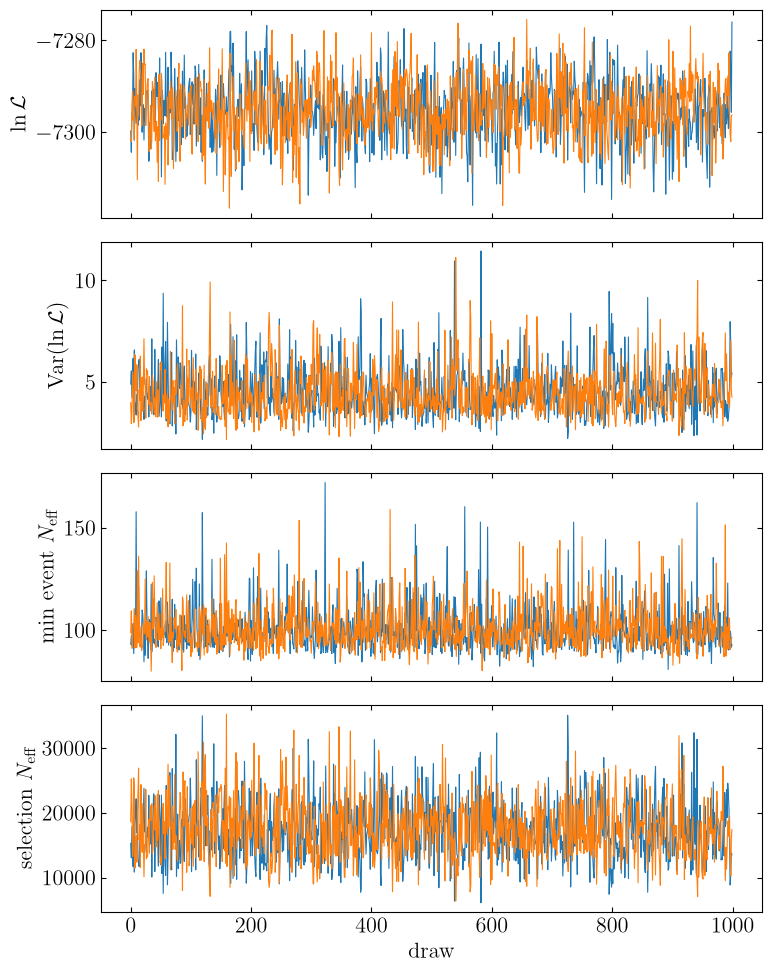

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(8, 10), sharex=True)
for i, c in enumerate(range(S['log_likelihood'].shape[0])):
    for ax, y in zip(axes, (S['log_likelihood'][c], S['log_likelihood_variance'][c], emin[c], S['selection_neff'][c])):
        ax.plot(y, lw=0.8, color=f'C{c}')
for ax, lab in zip(axes, (r'$\ln \mathcal{L}$', r'$\mathrm{Var}(\ln \mathcal{L})$', r'min event $N_\mathrm{eff}$',
                          r'selection $N_\mathrm{eff}$')):
    ax.set_ylabel(lab)
axes[-1].set_xlabel('draw')
fig.tight_layout()
plot_style.save(fig, f'{RUN}_traces')

## Events with the smallest effective sample size

The likelihood tapers events below $N_\mathrm{eff} = 100$; these are the events closest to that floor, by their median
over the draws.

In [5]:
DATA_DIRS = {'gwtc5': os.path.join(REPO, 'data', 'gwtc5_ifar1_chieffchip', 'data')}
directory = DATA_DIRS.get(CATALOG, f'/home/jack.heinzel/public_html/mass-gap-investigation/data/{CATALOG}_o1o4b_chieffchip/data')
import re
with open(os.path.join(directory, 'posteriors.pkl'), 'rb') as f:
    names = [re.findall(r'GW\d{6}(?:_\d{6})?', os.path.basename(str(n)))[-1] for n in pickle.load(f)['event_names']]
if len(names) != flat['event_neff'].shape[1]:
    print(f'event names ({len(names)}) do not match the chain ({flat["event_neff"].shape[1]} events): not labelled')
    names = [str(i) for i in range(flat['event_neff'].shape[1])]
neff = pd.DataFrame({'median': np.median(flat['event_neff'], 0), 'lo5': np.percentile(flat['event_neff'], 5, 0),
                     'frac < 100': (flat['event_neff'] < 100).mean(0)}, index=names)
neff.sort_values('median').head(12).round(2)

,median,lo5,frac < 100
GW191127_050227,115.830002,92.220001,0.19
GW200216_220804,122.779999,94.599998,0.12
GW240526_093944,127.949997,93.230003,0.15
GW190805_211137,169.080002,100.260002,0.05
GW241116_151753,173.300003,106.019997,0.02
GW240618_071627,181.669998,103.089996,0.04
GW241114_024711,217.279999,122.610001,0.01
GW240107_013215,221.770004,118.080002,0.01
GW230630_125806,234.940002,159.350006,0.00
GW231230_170116,239.550003,130.740005,0.00


## Masses

The saved `log_p_mass` is the mass field normalized on the grid **without** the $m_2 > 3\,M_\odot$ window, which acts
only on the event and injection weights. Here the window is added on bin centres, and the density renormalized,
before any marginal is taken.

In [6]:
logW = np.asarray(PlanckWindow_SecondaryMass({'log_mass_1': lnm_c[:, None], 'mass_ratio': q_c[None]}, MIN_M, 0.))
lp = flat['log_p_mass'] + logW[None]
lp -= np.log(np.exp(lp - lp.max((1, 2), keepdims=True)).sum((1, 2), keepdims=True) * dlnm * dq) + lp.max((1, 2), keepdims=True)
p_mass = np.exp(lp)                                   # (draws, ln m1, q), density per (d ln m1 dq), windowed
p_lnm = p_mass.sum(2) * dq                            # p(ln m1)
p_q = p_mass.sum(1) * dlnm                            # p(q)
print('window: fraction of bins kept', (logW > -1).mean(), '; normalization check', np.allclose(p_lnm.sum(1) * dlnm, 1))

window: fraction of bins kept 0.7651 ; normalization check True


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_mass_marginals.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_mass_marginals.pdf'

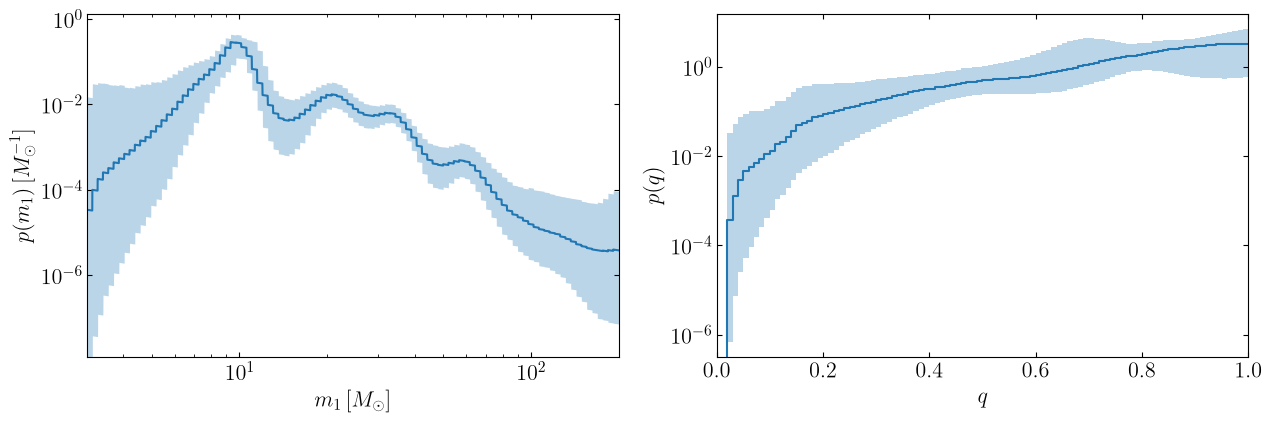

In [7]:
def band(x, axis=0):
    return np.percentile(x, [5, 50, 95], axis=axis)

N_FINE = 50
m_edges = np.exp(lnm_edges)
m_fine = np.concatenate([np.linspace(a, b, N_FINE, endpoint=False) for a, b in zip(m_edges[:-1], m_edges[1:])])
idx_fine = np.repeat(np.arange(100), N_FINE)
p_m1 = p_lnm[:, idx_fine] / m_fine[None]               # p(m1) = p(ln m1) / m1, smooth within each bin
lo, med, hi = band(p_m1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.fill_between(m_fine, lo, hi, color='C0', alpha=0.3, lw=0)
ax.plot(m_fine, med, color='C0')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(MIN_M, MAX_M); ax.set_ylim(np.percentile(lo, 1) / 3, hi.max() * 3)
ax.set_xlabel(r'$m_1\,[M_\odot]$'); ax.set_ylabel(r'$p(m_1)\,[M_\odot^{-1}]$')
ax = axes[1]
lo, med, hi = band(np.concatenate([p_q, p_q[:, -1:]], 1), 0)
ax.fill_between(q_edges, lo, hi, step='post', color='C0', alpha=0.3, lw=0)
ax.step(q_edges, med, where='post', color='C0')
ax.set_yscale('log'); ax.set_xlim(0, 1)
ax.set_xlabel(r'$q$'); ax.set_ylabel(r'$p(q)$')
fig.tight_layout()
plot_style.save(fig, f'{RUN}_mass_marginals')

/tmp/ipykernel_145162/1442331231.py:4: RuntimeWarning: divide by zero encountered in log10
  pc = ax.pcolormesh(np.exp(lnm_edges), q_edges, np.log10(np.maximum(med2, 1e-300)).T, vmin=vmin, vmax=vmax,


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_mass_joint.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_mass_joint.pdf'

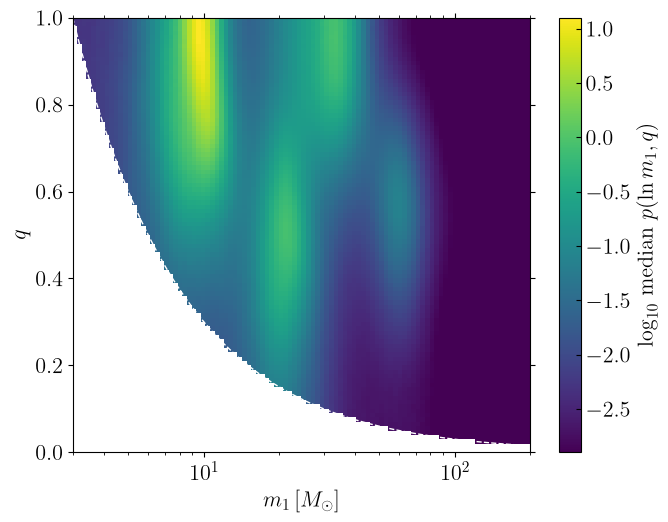

In [8]:
med2 = np.median(p_mass, 0)
fig, ax = plt.subplots(figsize=(7, 5.5))
vmax = np.log10(med2.max()); vmin = vmax - 4
pc = ax.pcolormesh(np.exp(lnm_edges), q_edges, np.log10(np.maximum(med2, 1e-300)).T, vmin=vmin, vmax=vmax,
                   cmap='viridis', shading='flat', rasterized=True)
ax.plot(np.exp(lnm_edges), np.clip(MIN_M / np.exp(lnm_edges), 0, 1), color='w', lw=1, ls='--')
ax.set_xscale('log'); ax.set_xlim(MIN_M, MAX_M); ax.set_ylim(0, 1)
ax.tick_params(which='both', direction='out')
ax.set_xlabel(r'$m_1\,[M_\odot]$'); ax.set_ylabel(r'$q$')
cb = fig.colorbar(pc, ax=ax); cb.set_label(r'$\log_{10}$ median $p(\ln m_1, q)$')
fig.tight_layout()
plot_style.save(fig, f'{RUN}_mass_joint')

### The primary-mass distribution at different mass ratios

$p(m_1 \mid q \in [q_\mathrm{lo}, q_\mathrm{hi}])$ from the windowed field: the field is summed over the $q$ bins in
each range, normalized within the range, and drawn as a density in linear $m_1$ ($p(m_1) = p(\ln m_1)/m_1$ within each
bin). The legend gives each range's share of the population, $P(q \in \mathrm{range})$. The dotted line marks the
smallest $m_1$ allowed by $m_2 > 3\,M_\odot$ at the range's lower edge; below it only the upper part of the range
contributes.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_m1_given_q.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_m1_given_q.pdf'

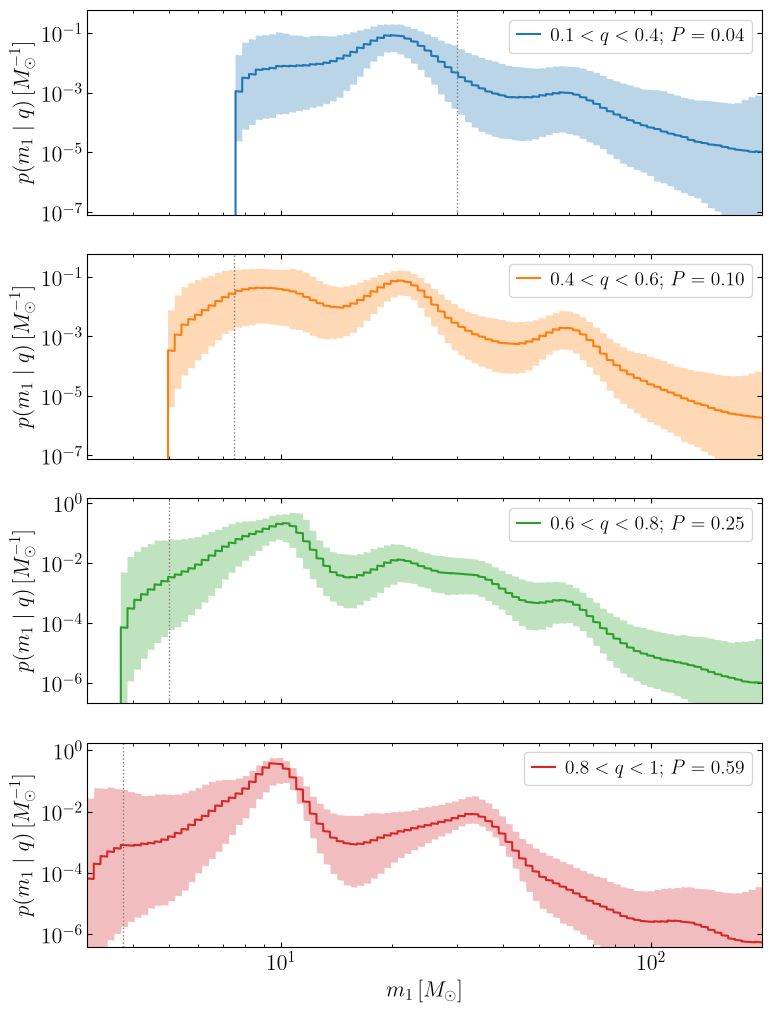

In [9]:
Q_RANGES = [(0.1, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
fig, axes = plt.subplots(len(Q_RANGES), 1, figsize=(8, 2.6 * len(Q_RANGES)), sharex=True)
for j, ((qlo, qhi), ax) in enumerate(zip(Q_RANGES, axes)):
    sel = (q_edges[:-1] >= qlo - 1e-9) & (q_edges[1:] <= qhi + 1e-9)
    p_lnm_q = p_mass[:, :, sel].sum(2) * dq                       # (draws, ln m1): p(ln m1, q in range)
    share = p_lnm_q.sum(1) * dlnm
    y = (p_lnm_q / share[:, None])[:, idx_fine] / m_fine[None]
    lo, med, hi = band(y)
    ax.fill_between(m_fine, lo, hi, color=f'C{j}', alpha=0.3, lw=0)
    ax.plot(m_fine, med, color=f'C{j}', label=rf'${qlo:g} < q < {qhi:g}$; $P = {np.median(share):.2f}$')
    ax.axvline(MIN_M / qlo, color='0.5', ls=':', lw=1)
    ax.set_yscale('log'); ax.set_ylim(max(np.percentile(lo, 1), med.max() * 1e-6), hi.max() * 3)
    ax.set_ylabel(r'$p(m_1 \mid q)\,[M_\odot^{-1}]$')
    ax.legend(loc='upper right', **plot_style.LEG_KW)
axes[-1].set_xscale('log'); axes[-1].set_xlim(MIN_M, MAX_M); axes[-1].set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout()
plot_style.save(fig, f'{RUN}_m1_given_q')

## Spins: the population marginal

The population's $(\chi_\mathrm{eff}, \chi_p)$ distribution is the spin conditional averaged over the mass distribution.
The saved `log_p_spin_marginal` averages with the mass weights **before** the $m_2 > 3\,M_\odot$ window. The data
never see the windowed-out corner ($q < 3/m_1$), so the field is unconstrained there. It carries a sizeable,
prior-driven share of the unwindowed mass probability (printed below), and with it that corner's spins. So the
marginal is rebuilt here from the saved spin field (`_spin_sites` and the spin hyperparameters, exactly as `model.py`
builds it, on every draw; `notebooks/analysis.py`, cached in `results/post_processing/for_plotting/`) and averaged
with the **windowed** mass weights. The rebuild is checked against the saved marginal, using the unwindowed weights;
differences of order $10^{-3}$ come from the chain being stored in float32.

In [10]:
sys.path.insert(0, os.path.join(REPO, 'notebooks'))
import analysis as A
r = A.load_run(RUN)              # spins: every draw, cached in results/post_processing/for_plotting/<RUN>/
print('spins', r.spin_source)
P_raw, P_win, MOM = r.P_raw, r.P_win, r.MOM          # MOM: (draws, ln m1, q, 4)
tv_win = 0.5 * np.abs(P_win - P_raw).sum((1, 2))
removed = r.window_removed
print(f'rebuild vs saved marginal, total variation: max {r.rebuild_tv:.1e}')
print('mass probability the window removes: median %.3f, 90%% [%.3f, %.3f]' % tuple(np.percentile(removed, [50, 5, 95])))
print('windowed vs unwindowed spin marginal, total variation: median %.3f, 90%% [%.3f, %.3f]'
      % tuple(np.percentile(tv_win, [50, 5, 95])))

spins rebuilt from the saved spin latents on all 1000 draws per chain (results/post_processing/for_plotting/ppc_gwtc5_k5/)
rebuild vs saved marginal, total variation: max 3.4e-03
mass probability the window removes: median 0.087, 90% [0.008, 0.794]
windowed vs unwindowed spin marginal, total variation: median 0.060, 90% [0.006, 0.655]


Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_spin_marginal.pdf
population spin moments, median [5%, 95%] over draws


,windowed,unwindowed (saved)
mean chi_eff,"0.033 [-0.075, 0.064]","0.034 [-0.222, 0.180]"
sd chi_eff,"0.140 [0.097, 0.348]","0.181 [0.108, 0.449]"
P(chi_eff < 0),"0.303 [0.192, 0.440]","0.317 [0.173, 0.598]"
mean chi_p,"0.230 [0.178, 0.290]","0.237 [0.154, 0.367]"


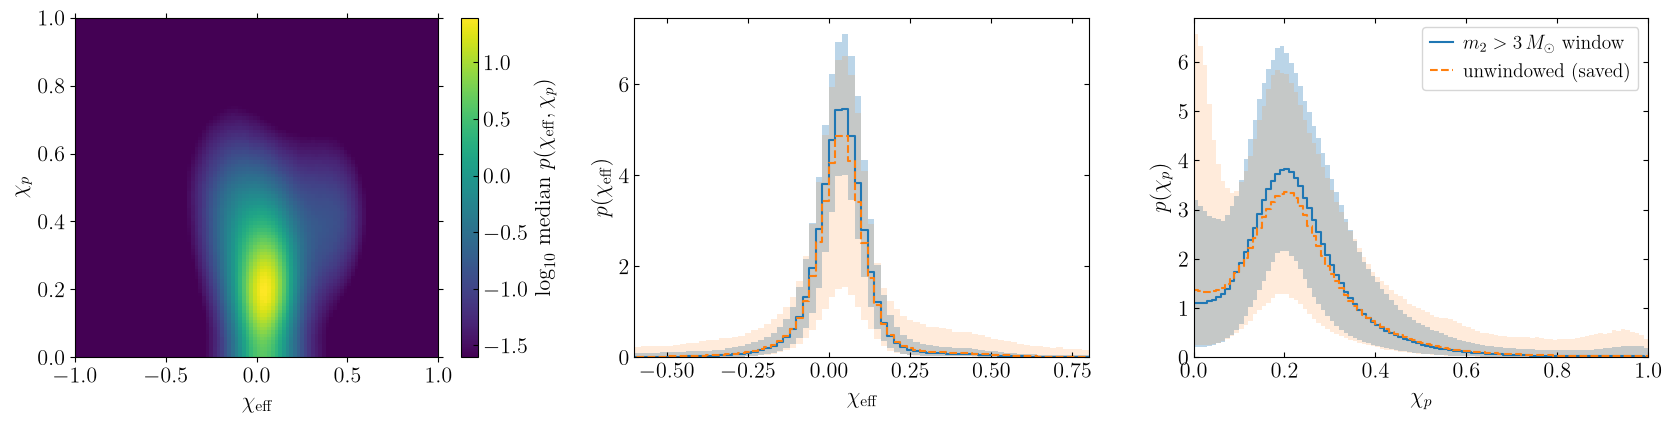

In [11]:
def spin_1d(P):
    return P.sum(2) / de, P.sum(1) / dp

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
med2 = np.median(P_win, 0) / (de * dp)
ax = axes[0]
vmax = np.log10(med2.max()); vmin = vmax - 3
pc = ax.pcolormesh(e_edges, p_edges, np.log10(np.maximum(med2, 1e-300)).T, vmin=vmin, vmax=vmax, cmap='viridis',
                   shading='flat', rasterized=True)
ax.tick_params(which='both', direction='out')
ax.set_xlabel(r'$\chi_\mathrm{eff}$'); ax.set_ylabel(r'$\chi_p$')
cb = fig.colorbar(pc, ax=ax); cb.set_label(r'$\log_{10}$ median $p(\chi_\mathrm{eff}, \chi_p)$')
for P, col, lab in ((P_win, 'C0', r'$m_2 > 3\,M_\odot$ window'), (P_raw, 'C1', 'unwindowed (saved)')):
    for ax, y, edges in zip(axes[1:], spin_1d(P), (e_edges, p_edges)):
        lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
        ax.fill_between(edges, lo, hi, step='post', color=col, alpha=0.3 if col == 'C0' else 0.15, lw=0)
        ax.step(edges, med, where='post', color=col, ls='-' if col == 'C0' else '--', label=lab)
for ax, edges, lab in ((axes[1], e_edges, r'\chi_\mathrm{eff}'), (axes[2], p_edges, r'\chi_p')):
    ax.set_xlim(edges[0], edges[-1]); ax.set_ylim(0)
    ax.set_xlabel(rf'${lab}$'); ax.set_ylabel(rf'$p({lab})$')
axes[1].set_xlim(-0.6, 0.8)
axes[2].legend(**plot_style.LEG_KW)
fig.tight_layout()
plot_style.save(fig, f'{RUN}_spin_marginal')

def moments(P):
    p_e, p_p = spin_1d(P)
    mean_e = (p_e * e_c).sum(1) * de
    return pd.DataFrame({'mean chi_eff': mean_e,
                         'sd chi_eff': np.sqrt((p_e * e_c ** 2).sum(1) * de - mean_e ** 2),
                         'P(chi_eff < 0)': (p_e * (e_c < 0)).sum(1) * de,
                         'mean chi_p': (p_p * p_c).sum(1) * dp})
fmt = lambda df: df.quantile([0.05, 0.5, 0.95]).T.apply(lambda r: f'{r[0.5]:.3f} [{r[0.05]:.3f}, {r[0.95]:.3f}]', axis=1)
print('population spin moments, median [5%, 95%] over draws')
pd.DataFrame({'windowed': fmt(moments(P_win)), 'unwindowed (saved)': fmt(moments(P_raw))})

## Spins as a function of mass

`log_p_spin_q1_m` holds the spin conditional $p(\chi_\mathrm{eff}, \chi_p \mid m_1, q)$ in the top $q$ bin
($q \approx 1$) at 10, 18, 35, 60$\,M_\odot$, the masses saved by the
model (`model.SPIN_REF_MASSES`). These slices show how much the spin distribution is allowed, and needs, to change with
mass. At $q \approx 1$ the physical region is $\chi_p < \sqrt{1 - \max(0, 2|\chi_\mathrm{eff}| - 1)^2}$.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_spin_given_m1.pdf
median [5%, 95%] over draws, at q ~ 1


,10 Msun,18 Msun,35 Msun,60 Msun
mean chi_eff,"0.041 [-0.014, 0.079]","0.035 [-0.006, 0.071]","0.014 [-0.036, 0.048]","0.031 [-0.214, 0.214]"
sd chi_eff,"0.073 [0.048, 0.240]","0.076 [0.052, 0.166]","0.107 [0.072, 0.223]","0.188 [0.094, 0.386]"
P(chi_eff < 0),"0.227 [0.065, 0.425]","0.284 [0.119, 0.490]","0.450 [0.276, 0.633]","0.444 [0.146, 0.826]"
mean chi_p,"0.213 [0.146, 0.292]","0.241 [0.174, 0.323]","0.290 [0.219, 0.380]","0.375 [0.210, 0.569]"


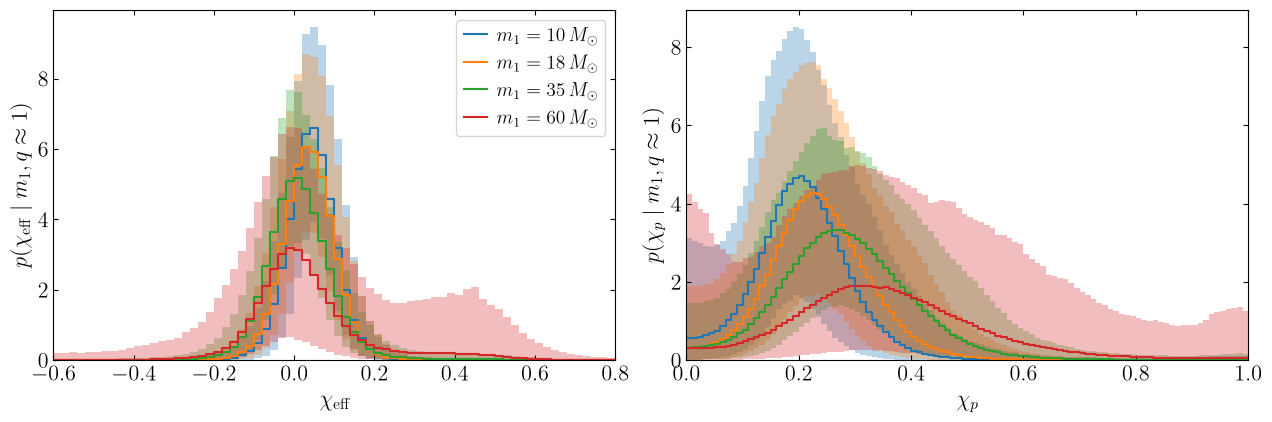

In [12]:
Pm = np.exp(flat['log_p_spin_q1_m'])                   # (draws, n_masses, chi_eff, chi_p), probability per bin
Pm /= Pm.sum((2, 3), keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for j, m in enumerate(SPIN_REF_MASSES):
    for ax, y, edges in ((axes[0], Pm[:, j].sum(2) / de, e_edges), (axes[1], Pm[:, j].sum(1) / dp, p_edges)):
        lo, med, hi = band(np.concatenate([y, y[:, -1:]], 1))
        ax.fill_between(edges, lo, hi, step='post', color=f'C{j}', alpha=0.3, lw=0)
        ax.step(edges, med, where='post', color=f'C{j}', label=rf'$m_1 = {m:g}\,M_\odot$')
axes[0].set_xlim(-0.6, 0.8); axes[1].set_xlim(0, 1)
for ax, lab in zip(axes, (r'\chi_\mathrm{eff}', r'\chi_p')):
    ax.set_ylim(0); ax.set_xlabel(rf'${lab}$'); ax.set_ylabel(rf'$p({lab} \mid m_1, q \approx 1)$')
axes[0].legend(**plot_style.LEG_KW)
fig.tight_layout()
plot_style.save(fig, f'{RUN}_spin_given_m1')

rows = {}
for j, m in enumerate(SPIN_REF_MASSES):
    pe_j = Pm[:, j].sum(2) / de; pp_j = Pm[:, j].sum(1) / dp
    mean_e = (pe_j * e_c).sum(1) * de
    rows[f'{m:g} Msun'] = {
        'mean chi_eff': np.percentile(mean_e, [5, 50, 95]),
        'sd chi_eff': np.percentile(np.sqrt((pe_j * e_c ** 2).sum(1) * de - mean_e ** 2), [5, 50, 95]),
        'P(chi_eff < 0)': np.percentile((pe_j * (e_c < 0)).sum(1) * de, [5, 50, 95]),
        'mean chi_p': np.percentile((pp_j * p_c).sum(1) * dp, [5, 50, 95])}
table = pd.DataFrame({m: {k: f'{v[1]:.3f} [{v[0]:.3f}, {v[2]:.3f}]' for k, v in r.items()} for m, r in rows.items()})
print('median [5%, 95%] over draws, at q ~ 1')
table

In [13]:
# difference between the heaviest and lightest slice, per draw: is the mass dependence resolved?
pe = Pm.sum(3) / de
mean_e = (pe * e_c).sum(2) * de                          # (draws, n_masses)
d = mean_e[:, -1] - mean_e[:, 0]
print(f'mean chi_eff at {SPIN_REF_MASSES[-1]:g} minus at {SPIN_REF_MASSES[0]:g} Msun (q ~ 1): '
      f'median {np.median(d):.3f}, 90% [{np.percentile(d, 5):.3f}, {np.percentile(d, 95):.3f}], P(> 0) {(d > 0).mean():.2f}')
sd = np.sqrt((pe * e_c ** 2).sum(2) * de - mean_e ** 2)
d = sd[:, -1] - sd[:, 0]
print(f'sd chi_eff, same difference: median {np.median(d):.3f}, 90% [{np.percentile(d, 5):.3f}, {np.percentile(d, 95):.3f}], '
      f'P(> 0) {(d > 0).mean():.2f}')

mean chi_eff at 60 minus at 10 Msun (q ~ 1): median -0.007, 90% [-0.278, 0.212], P(> 0) 0.46
sd chi_eff, same difference: median 0.105, 90% [-0.060, 0.304], P(> 0) 0.90


## Spin moments as a function of primary mass

The mean and standard deviation of $\chi_\mathrm{eff}$ and $\chi_p$ under the spin conditional
$p(\chi_\mathrm{eff}, \chi_p \mid m_1, q)$, in every $m_1$ bin, from the rebuilt field. Bands are 90% over draws. These
are properties of the conditional at fixed $(m_1, q)$, so they need no mass window; bins with $q\,m_1 < 3\,M_\odot$
are dropped because the population has no support there. Where the data are sparse the bands widen towards the
zero-field limit, a flat density on the physical region: mean $\chi_\mathrm{eff} = 0$, sd $\chi_\mathrm{eff} = 0.51$–$0.53$,
mean $\chi_p = 0.45$–$0.47$, sd $\chi_p = 0.27$–$0.28$ (for $q = 0.3$–$1$). The field's prior spreads draws around that
limit, not onto it.

First at $q \approx 1$ (the top $q$ bin, $0.99 < q < 1$):

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_spin_moments_q1.pdf
q ~ 1: median [5%, 95%] over draws


,mean chi_eff,sd chi_eff,mean chi_p,sd chi_p
m1 [Msun],,,,
8.0,"0.038 [-0.063, 0.088]","0.075 [0.047, 0.306]","0.203 [0.123, 0.294]","0.089 [0.051, 0.170]"
9.9,"0.041 [-0.014, 0.079]","0.073 [0.048, 0.240]","0.213 [0.146, 0.292]","0.088 [0.052, 0.154]"
15.1,"0.039 [-0.002, 0.075]","0.074 [0.050, 0.177]","0.232 [0.167, 0.312]","0.090 [0.056, 0.141]"
20.3,"0.031 [-0.009, 0.065]","0.079 [0.054, 0.164]","0.249 [0.179, 0.330]","0.097 [0.062, 0.145]"
29.6,"0.018 [-0.022, 0.048]","0.095 [0.065, 0.194]","0.275 [0.205, 0.357]","0.113 [0.075, 0.162]"
39.7,"0.014 [-0.057, 0.059]","0.120 [0.075, 0.260]","0.303 [0.221, 0.405]","0.129 [0.083, 0.194]"
60.4,"0.031 [-0.213, 0.214]","0.188 [0.094, 0.386]","0.375 [0.210, 0.568]","0.165 [0.092, 0.270]"
100.0,"0.082 [-0.507, 0.421]","0.225 [0.089, 0.496]","0.488 [0.184, 0.816]","0.185 [0.075, 0.323]"


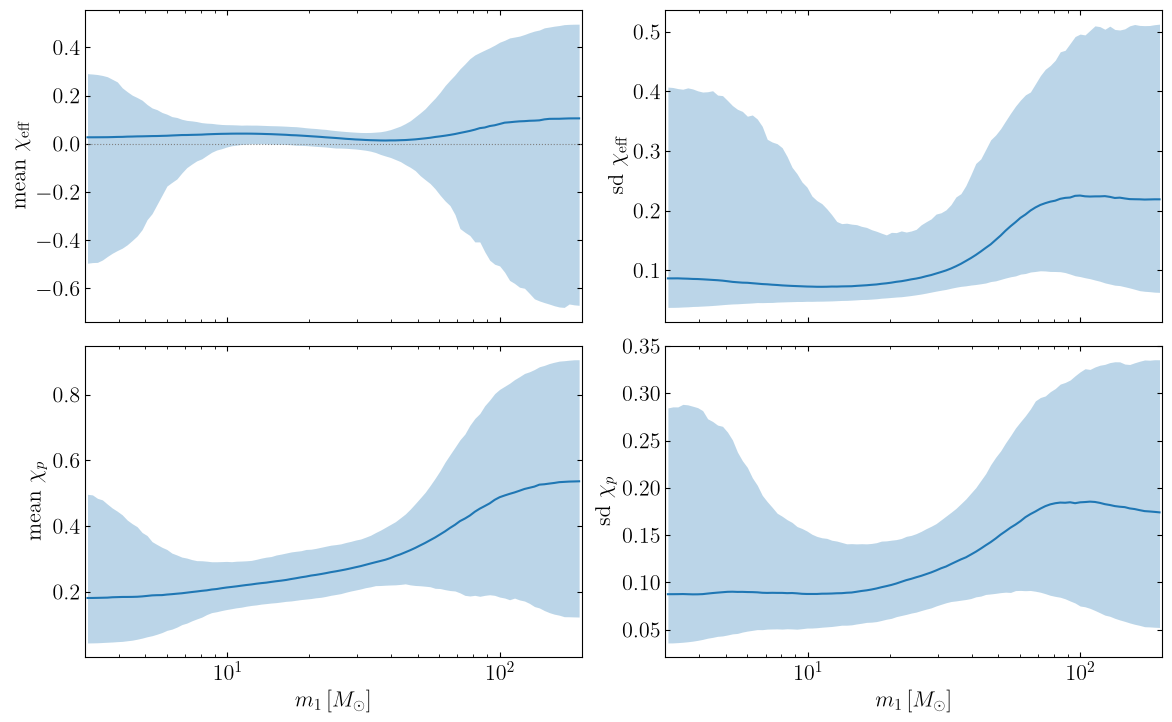

In [14]:
MOM_LABELS = [r'mean $\chi_\mathrm{eff}$', r'sd $\chi_\mathrm{eff}$', r'mean $\chi_p$', r'sd $\chi_p$']
m_c = np.exp(lnm_c)

def moment_panels(axes, iq, col, label=None):
    ok = q_c[iq] * m_c >= MIN_M
    for k, ax in enumerate(axes):
        lo, med, hi = band(MOM[:, ok, iq, k])
        ax.fill_between(m_c[ok], lo, hi, color=col, alpha=0.3, lw=0)
        ax.plot(m_c[ok], med, color=col, label=label)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
moment_panels(axes.ravel(), -1, 'C0')
for ax, lab in zip(axes.ravel(), MOM_LABELS):
    ax.set_ylabel(lab); ax.set_xscale('log'); ax.set_xlim(MIN_M, MAX_M)
axes[0, 0].axhline(0, color='0.5', lw=0.8, ls=':')
for ax in axes[1]:
    ax.set_xlabel(r'$m_1\,[M_\odot]$')
fig.tight_layout()
plot_style.save(fig, f'{RUN}_spin_moments_q1')

rows = []
for m in (8., 10., 15., 20., 30., 40., 60., 100.):
    im = int(np.argmin(np.abs(m_c - m)))
    rows.append({'m1 [Msun]': f'{m_c[im]:.1f}', **{lab: '%.3f [%.3f, %.3f]' % (np.median(MOM[:, im, -1, k]),
                                                                           *np.percentile(MOM[:, im, -1, k], [5, 95]))
                 for k, lab in enumerate(('mean chi_eff', 'sd chi_eff', 'mean chi_p', 'sd chi_p'))}})
print('q ~ 1: median [5%, 95%] over draws')
pd.DataFrame(rows).set_index('m1 [Msun]')

Then in $q$ slices, one row per slice (the $q$ bin nearest each value), so the bands do not overlap. A slice's
curve starts at $m_1 = 3\,M_\odot / q$.

Saved /mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_spin_moments_q_slices.pdf


'/mnt/home/jheinzel/bbh-pixelpop-constraints/plots/ppc_gwtc5_k5_spin_moments_q_slices.pdf'

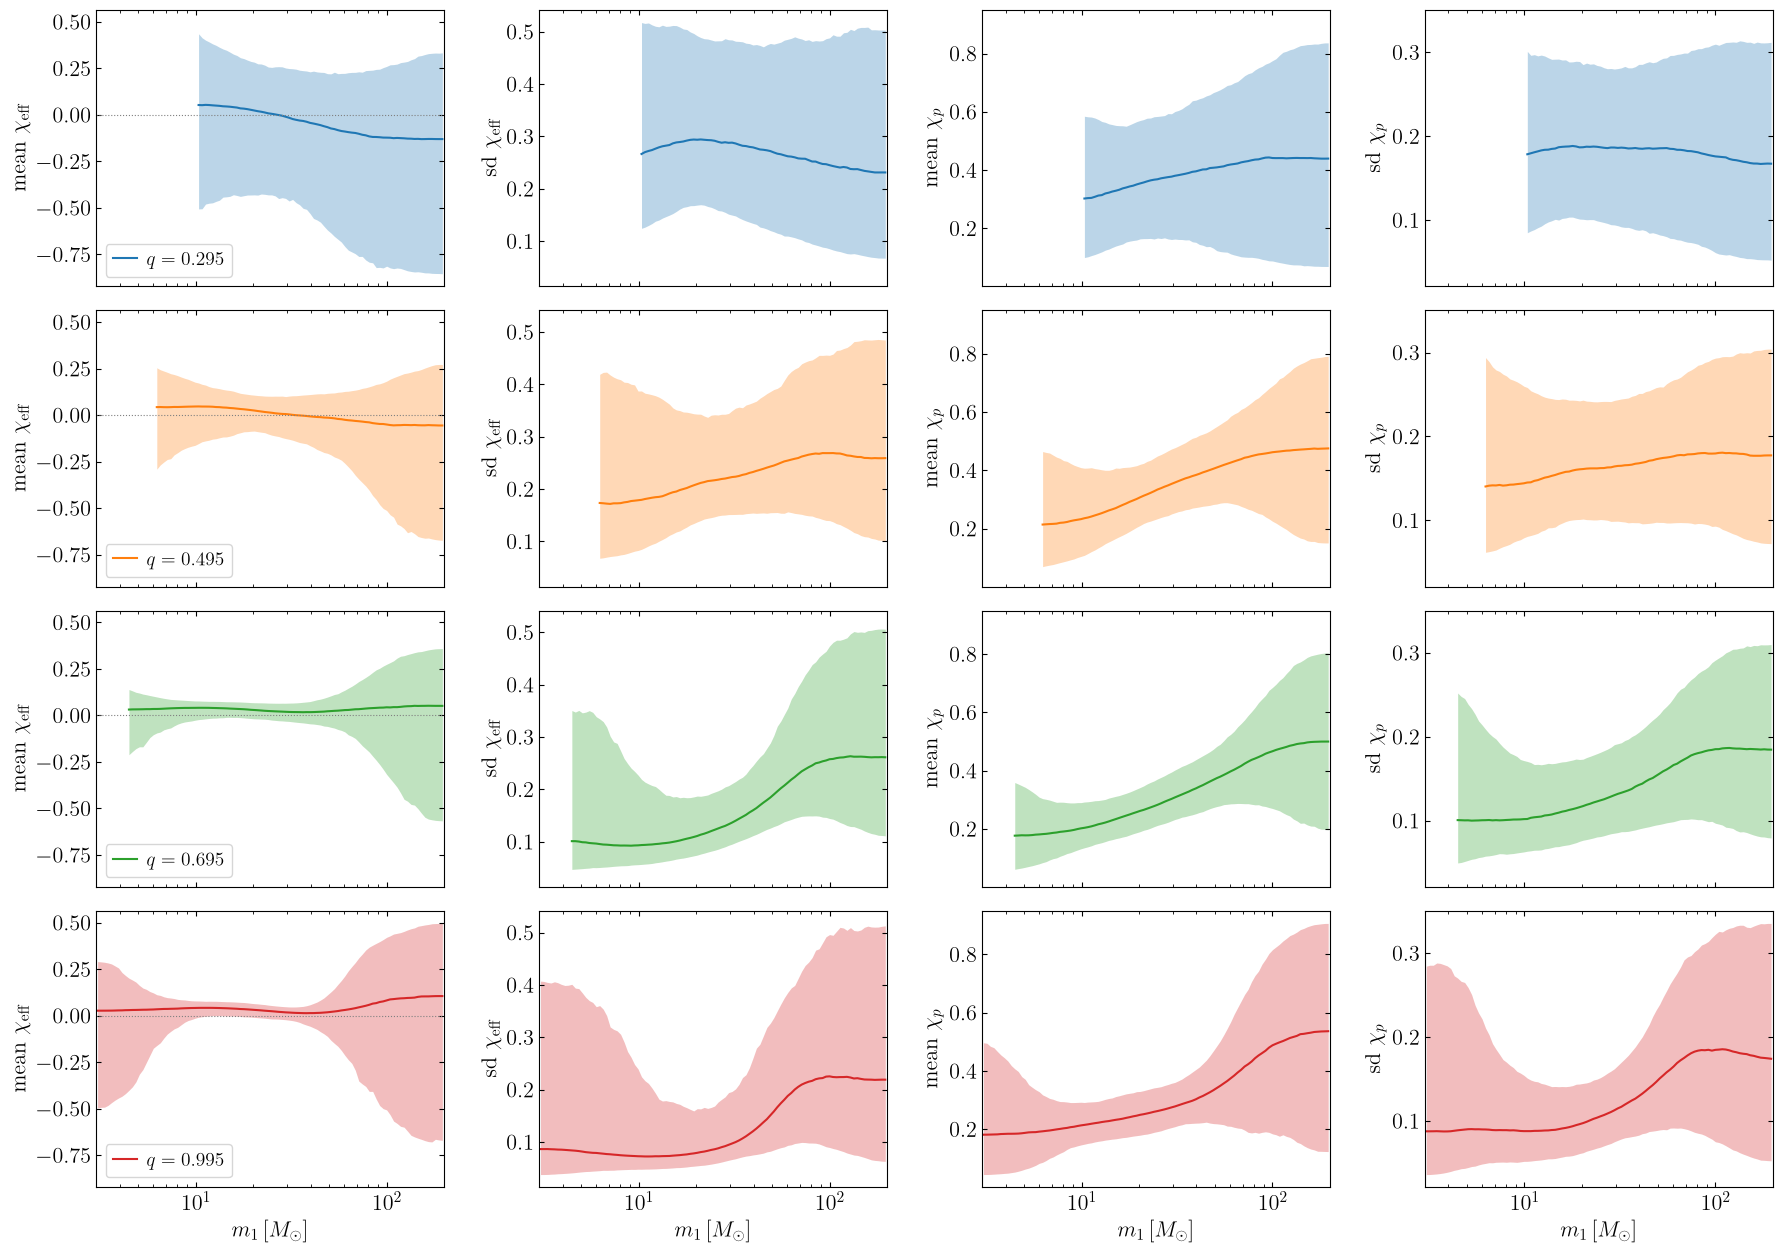

In [15]:
Q_SLICES = (0.3, 0.5, 0.7, 1.0)
fig, axes = plt.subplots(len(Q_SLICES), 4, figsize=(18, 3.2 * len(Q_SLICES)), sharex=True, sharey='col')
for r, qv in enumerate(Q_SLICES):
    iq = int(np.argmin(np.abs(q_c - qv)))
    moment_panels(axes[r], iq, f'C{r}', label=rf'$q = {q_c[iq]:.3f}$')
    axes[r, 0].legend(loc='lower left', **plot_style.LEG_KW)
    axes[r, 0].axhline(0, color='0.5', lw=0.8, ls=':')
for c, lab in enumerate(MOM_LABELS):
    axes[-1, c].set_xlabel(r'$m_1\,[M_\odot]$')
    for r in range(len(Q_SLICES)):
        axes[r, c].set_ylabel(lab)
axes[0, 0].set_xscale('log'); axes[0, 0].set_xlim(MIN_M, MAX_M)
fig.tight_layout()
plot_style.save(fig, f'{RUN}_spin_moments_q_slices')

## Model-specific parameters

- **`split`:** $\sigma_1$ is the marginal sd of the mass-varying part $G_1$ of the spin log density, and $\sigma_0$
  that of the mass-independent part $G_0$. Both have PixelPop's prior, $\ln\sigma \sim N(0, 2)$. A $\sigma_1$
  posterior pushed well above its prior's low tail means the data ask for spins that change with mass.
- **`gauss`:** the correlation $\rho(m_1)$ of the Gaussian at $q \approx 1$ (its other parameters show up through the
  moments above). The parameters $\mu$ and $\sigma$ are those of the Gaussian *before* truncation to the physical
  region, so they differ from the moments, which are of the truncated distribution.
- **`field`:** nothing extra.

In [16]:
if SPIN_MODEL == 'split':
    import scipy.stats as st
    fig, ax = plt.subplots(figsize=(7, 4.5))
    x = np.linspace(-6, 4, 400)
    for k, col, lab in (('lnsigma_spin0', 'C0', r'$\ln\sigma_0$ (mass-independent)'),
                        ('lnsigma_spin1', 'C1', r'$\ln\sigma_1$ (mass-varying)')):
        ax.hist(flat[k], bins=30, density=True, color=col, alpha=0.5, label=lab)
    ax.plot(x, st.norm(0, 2).pdf(x), color='0.4', ls='--', label='prior')
    ax.set_xlabel(r'$\ln\sigma$'); ax.set_ylabel('density'); ax.legend(**plot_style.LEG_KW)
    fig.tight_layout(); plot_style.save(fig, f'{RUN}_split_sigmas')
    l1 = flat['lnsigma_spin1']
    print('ln sigma_1: median %.2f, 90%% [%.2f, %.2f]; P(sigma_1 > sigma_0) %.2f'
          % (np.median(l1), *np.percentile(l1, [5, 95]), (l1 > flat['lnsigma_spin0']).mean()))
    print('prior P(ln sigma_1 < 5th percentile of the posterior) = %.3f' % st.norm(0, 2).cdf(np.percentile(l1, 5)))
elif SPIN_MODEL == 'gauss':
    th = flat['gauss_params']                                    # (draws, 5, ln m1, q)
    m_c = np.exp(lnm_c)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    lo, med, hi = band(np.tanh(th[:, 4, :, -1]))
    ax.fill_between(m_c, lo, hi, color='C0', alpha=0.3, lw=0); ax.plot(m_c, med, color='C0')
    ax.axhline(0, color='0.5', lw=0.8, ls=':')
    ax.set_xscale('log'); ax.set_xlim(MIN_M, MAX_M); ax.set_ylim(-1, 1)
    ax.set_xlabel(r'$m_1\,[M_\odot]$'); ax.set_ylabel(r'$\rho(\chi_\mathrm{eff}, \chi_p \mid m_1, q \approx 1)$')
    fig.tight_layout(); plot_style.save(fig, f'{RUN}_gauss_rho')
else:
    print('field model: no extra parameters')

field model: no extra parameters
